# Tarea 4: convoluciones, MLP y CNN con CIFAR-10

Solución reproducible en PyTorch. Usa los archivos CIFAR-10 ya incluidos en `cifar-10-batches-py`; no descarga datos. Ejecute las celdas en orden. El entrenamiento es una demostración reproducible con una muestra estratificada de 10 000 imágenes de entrenamiento (8 000 para entrenar y 2 000 para validar); el conjunto oficial de prueba se reserva hasta la sección final.

**Nota experimental:** el valor predeterminado de 3 épocas mantiene razonable el tiempo de ejecución en CPU. Para resultados más competitivos, aumente `EPOCHS` y, si cuenta con memoria suficiente, `MAX_TRAIN_SAMPLES`.

## 1. Convolución a mano

Usamos la correlación cruzada que implementa `nn.Conv2d` (sin invertir el filtro). Para cada ventana, la salida es la suma de la fila superior de `X` menos la fila inferior, pues la fila central de `K` es cero.

In [1]:
import torch
from torch import nn
import torch.nn.functional as F

X = torch.tensor([[1, 0, 2, 1, 0],
                  [0, 1, 1, 0, 2],
                  [2, 3, 0, 1, 1],
                  [1, 1, 0, 2, 1],
                  [0, 1, 2, 1, 0]], dtype=torch.float32)
K = torch.tensor([[1, 1, 1], [0, 0, 0], [-1, -1, -1]], dtype=torch.float32)

# Cálculo explícito de cada ventana 3x3.
salida_manual = torch.empty((3, 3))
for i in range(3):
    for j in range(3):
        salida_manual[i, j] = (X[i:i+3, j:j+3] * K).sum()
relu_manual = F.relu(salida_manual)
pool_manual = nn.MaxPool2d(kernel_size=2, stride=1)(relu_manual[None, None])[0, 0]
print('Convolución/correlación válida:')
print(salida_manual)
print('Después de ReLU:')
print(relu_manual)
print('Después de max pooling 2x2, stride 1:')
print(pool_manual)

# Verificación en PyTorch: peso asignado manualmente y sesgo desactivado.
conv = nn.Conv2d(1, 1, kernel_size=3, stride=1, padding=0, bias=False)
with torch.no_grad():
    conv.weight.copy_(K[None, None])
salida_torch = conv(X[None, None])[0, 0]
pool_torch = nn.MaxPool2d(2, stride=1)(F.relu(salida_torch)[None, None])[0, 0]
assert torch.equal(salida_manual, salida_torch)
assert torch.equal(pool_manual, pool_torch)
print('Verificación nn.Conv2d y nn.MaxPool2d: correcta')

# Parámetros, incluyendo el sesgo predeterminado de Conv2d.
conv_params = 16 * 3 * 3 * 3 + 16
dense_params = (32 * 32 * 3) * (30 * 30 * 16) + (30 * 30 * 16)
print(f'nn.Conv2d(3, 16, kernel_size=3): {conv_params:,} parámetros')
print(f'Capa densa 32x32x3 -> 30x30x16: {dense_params:,} parámetros')

Convolución/correlación válida:
tensor([[-2., -1.,  1.],
        [ 0., -1.,  0.],
        [ 2.,  0., -1.]])
Después de ReLU:
tensor([[0., 0., 1.],
        [0., 0., 0.],
        [2., 0., 0.]])
Después de max pooling 2x2, stride 1:
tensor([[0., 1.],
        [2., 0.]])
Verificación nn.Conv2d y nn.MaxPool2d: correcta
nn.Conv2d(3, 16, kernel_size=3): 448 parámetros
Capa densa 32x32x3 -> 30x30x16: 44,251,200 parámetros


El resultado esperado de la convolución es `[-2, -1, 1; 0, -1, 0; 2, 0, -1]`. Tras ReLU queda `[0, 0, 1; 0, 0, 0; 2, 0, 0]`; el max pooling produce `[0, 1; 2, 0]`. La convolución tiene **448** parámetros. La capa densa de la pregunta tiene **44 251 200** parámetros (incluye sesgos: 3 072 × 14 400 + 14 400).

## 2. Dataset, visualización y partición

CIFAR-10 tiene diez clases y 50 000 imágenes oficiales de entrenamiento más 10 000 de prueba, RGB de 32×32. Leemos directamente los archivos binarios locales. La partición train/validación se hace de forma estratificada y determinista; todos los modelos reutilizan exactamente los mismos índices.

Dispositivo: cpu
Dataset local: C:\Users\VICTUS\Documents\VSC\IA\Tarea4\cifar-10-batches-py


50,000 imágenes train oficiales; 10,000 imágenes test oficiales; clases: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


,clase,ejemplos,proporción
0,airplane,5000,0.1
1,automobile,5000,0.1
2,bird,5000,0.1
3,cat,5000,0.1
4,deer,5000,0.1
5,dog,5000,0.1
6,frog,5000,0.1
7,horse,5000,0.1
8,ship,5000,0.1
9,truck,5000,0.1


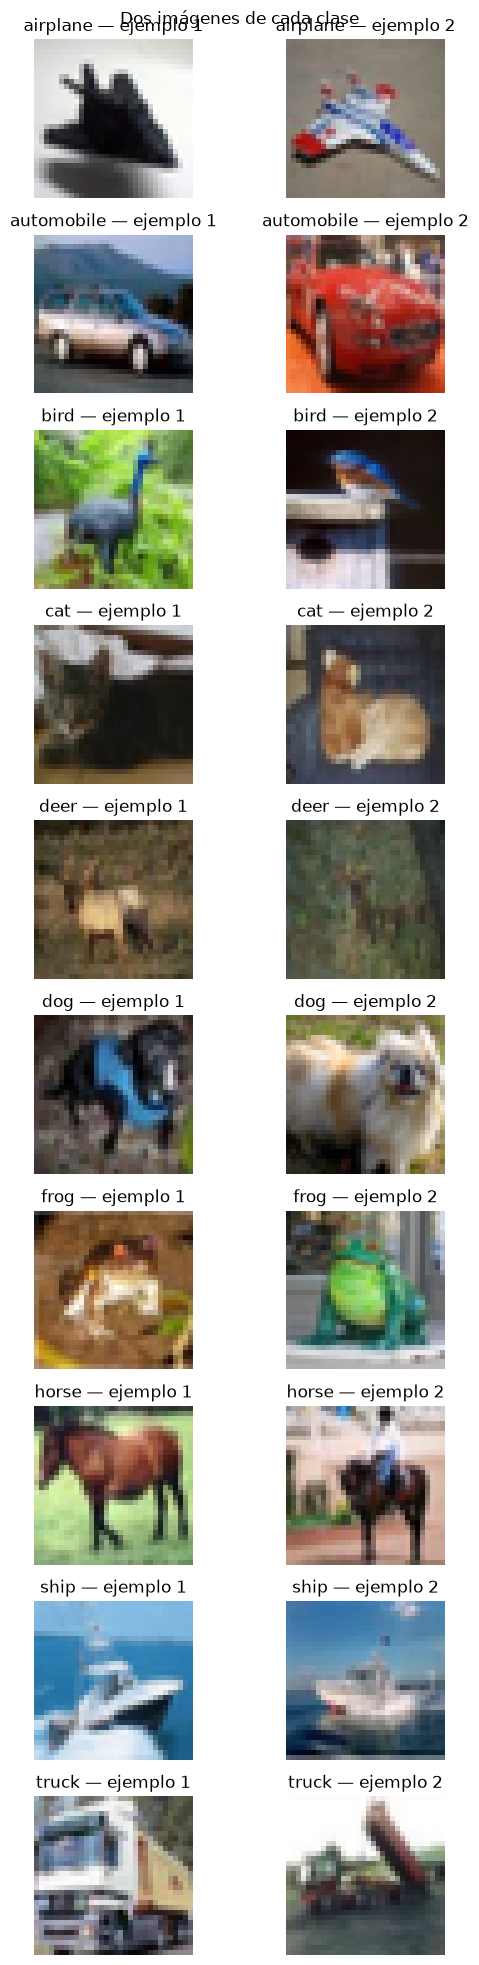

Train: 8000; validación: 2000; test reservado: 10000
Conteos train: [800 800 800 800 800 800 800 800 800 800]
Conteos validación: [200 200 200 200 200 200 200 200 200 200]


In [2]:
import pickle
from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from torch.utils.data import Dataset, DataLoader

SEED = 42
MAX_TRAIN_SAMPLES = 10_000
EPOCHS = 3
BATCH_SIZE = 128
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', device)

# Admite ejecutar el notebook desde Tarea4 o desde la carpeta raíz del proyecto.
candidatos = [Path.cwd(), Path.cwd() / 'Tarea4', Path.cwd().parent / 'Tarea4']
DATA_DIR = next((p / 'cifar-10-batches-py' for p in candidatos
                 if (p / 'cifar-10-batches-py' / 'data_batch_1').exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError('No se encontró Tarea4/cifar-10-batches-py/data_batch_1')
OUTPUT_DIR = DATA_DIR.parent
print('Dataset local:', DATA_DIR.resolve())

def leer_batch(ruta):
    with open(ruta, 'rb') as archivo:
        batch = pickle.load(archivo, encoding='bytes')
    imagenes = batch[b'data'].reshape(-1, 3, 32, 32)
    etiquetas = np.asarray(batch[b'labels'], dtype=np.int64)
    return imagenes, etiquetas

partes = [leer_batch(DATA_DIR / f'data_batch_{i}') for i in range(1, 6)]
x_todo = np.concatenate([p[0] for p in partes])
y_todo = np.concatenate([p[1] for p in partes])
x_test_np, y_test_np = leer_batch(DATA_DIR / 'test_batch')
with open(DATA_DIR / 'batches.meta', 'rb') as archivo:
    class_names = pickle.load(archivo, encoding='bytes')[b'label_names']
class_names = [n.decode('utf-8') if isinstance(n, bytes) else n for n in class_names]
assert len(x_todo) == 50_000 and len(x_test_np) == 10_000 and len(class_names) == 10
print(f'{len(x_todo):,} imágenes train oficiales; {len(x_test_np):,} imágenes test oficiales; clases: {class_names}')

# Proporción por clase en todo el conjunto oficial de entrenamiento.
conteos = np.bincount(y_todo, minlength=len(class_names))
display(pd.DataFrame({'clase': class_names, 'ejemplos': conteos,
                      'proporción': conteos / len(y_todo)}))

fig, axes = plt.subplots(10, 2, figsize=(6, 20))
for clase in range(len(class_names)):
    ejemplos = np.flatnonzero(y_todo == clase)[:2]
    for j, ax in enumerate(axes[clase]):
        ax.imshow(x_todo[ejemplos[j]].transpose(1, 2, 0))
        ax.set_title(f'{class_names[clase]} — ejemplo {j + 1}')
        ax.axis('off')
plt.suptitle('Dos imágenes de cada clase')
plt.tight_layout()
plt.show()

# Muestra aleatoria balanceada por clase y partición estratificada 80/20.
rng = np.random.default_rng(SEED)
por_clase = MAX_TRAIN_SAMPLES // len(class_names)
indices_muestra = np.concatenate([
    rng.choice(np.flatnonzero(y_todo == c), size=por_clase, replace=False)
    for c in range(len(class_names))
])
rng.shuffle(indices_muestra)
indices_train, indices_val = [], []
for c in range(len(class_names)):
    idx_c = indices_muestra[y_todo[indices_muestra] == c].copy()
    rng.shuffle(idx_c)
    n_train = int(0.8 * len(idx_c))
    indices_train.extend(idx_c[:n_train])
    indices_val.extend(idx_c[n_train:])
indices_train, indices_val = np.asarray(indices_train), np.asarray(indices_val)
rng.shuffle(indices_train)
rng.shuffle(indices_val)
print(f'Train: {len(indices_train)}; validación: {len(indices_val)}; test reservado: {len(y_test_np)}')
print('Conteos train:', np.bincount(y_todo[indices_train], minlength=10))
print('Conteos validación:', np.bincount(y_todo[indices_val], minlength=10))

class CIFARArrayDataset(Dataset):
    def __init__(self, images, labels):
        self.images = torch.from_numpy(np.ascontiguousarray(images))
        self.labels = torch.from_numpy(np.asarray(labels, dtype=np.int64))
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        return self.images[idx], self.labels[idx]

train_ds = CIFARArrayDataset(x_todo[indices_train], y_todo[indices_train])
val_ds = CIFARArrayDataset(x_todo[indices_val], y_todo[indices_val])
test_ds = CIFARArrayDataset(x_test_np, y_test_np)
def make_loaders(seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return (DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=generator, num_workers=0),
            DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=0),
            DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=0))
train_loader, val_loader, test_loader = make_loaders()
train_eval_loader = DataLoader(train_ds, batch_size=256, shuffle=False, num_workers=0)
CIFAR_MEAN = torch.tensor([0.4914, 0.4822, 0.4465], device=device).view(1, 3, 1, 1)
CIFAR_STD = torch.tensor([0.2470, 0.2435, 0.2616], device=device).view(1, 3, 1, 1)
def preparar_lote(images):
    return (images.to(device=device, dtype=torch.float32) / 255.0 - CIFAR_MEAN) / CIFAR_STD

## 3. MLP de referencia

Aplanamos cada imagen RGB de 32×32 y usamos una capa oculta con ReLU y dropout. La validación no participa en el gradiente; guardamos los mejores pesos por pérdida de validación y usamos parada temprana.

Época 1/3: loss=1.616, acc=0.436; val_loss=1.790, val_acc=0.384


Época 2/3: loss=1.447, acc=0.498; val_loss=1.693, val_acc=0.404


Época 3/3: loss=1.385, acc=0.524; val_loss=1.721, val_acc=0.414
Parámetros MLP: 789,258; mejor train acc=0.498; mejor validación acc=0.404


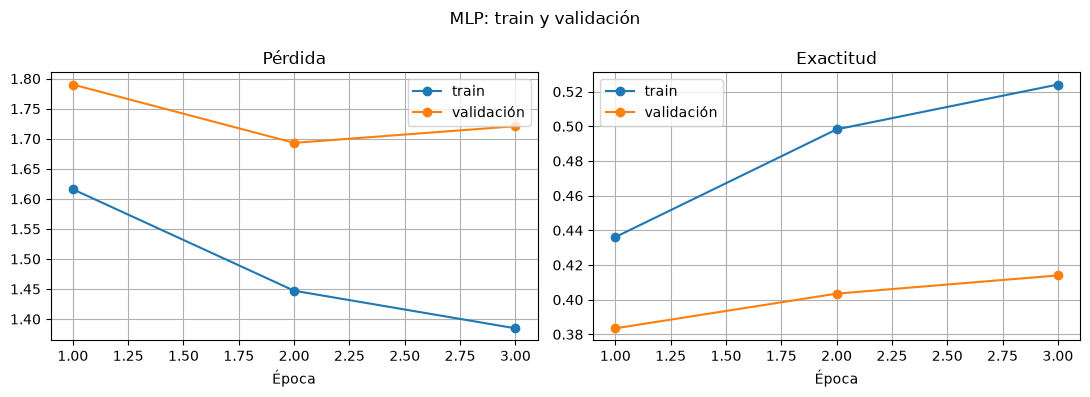

In [3]:
class MLP(nn.Module):
    def __init__(self, hidden=256, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(), nn.Linear(3 * 32 * 32, hidden), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden, 10))
    def forward(self, x):
        return self.net(x)

def evaluar(model, loader):
    model.eval()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = preparar_lote(images), labels.to(device)
            logits = model(images)
            loss_sum += F.cross_entropy(logits, labels, reduction='sum').item()
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.numel()
    return loss_sum / total, correct / total

def entrenar(model, epochs=EPOCHS, lr=1e-3, weight_decay=0.0, patience=2, seed=SEED):
    torch.manual_seed(seed)
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_loss, best_state, best_epoch, wait = float('inf'), None, 0, 0
    loader, _, _ = make_loaders(seed)
    for epoch in range(epochs):
        model.train()
        for images, labels in loader:
            images, labels = preparar_lote(images), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = F.cross_entropy(logits, labels)
            loss.backward()
            optimizer.step()
        # Medimos train y validación en modo eval para comparar ambas curvas sin dropout activo.
        tr_loss, tr_acc = evaluar(model, train_eval_loader)
        va_loss, va_acc = evaluar(model, val_loader)
        for key, value in [('train_loss', tr_loss), ('train_acc', tr_acc),
                           ('val_loss', va_loss), ('val_acc', va_acc)]:
            history[key].append(value)
        print(f'Época {epoch+1}/{epochs}: loss={tr_loss:.3f}, acc={tr_acc:.3f}; '
              f'val_loss={va_loss:.3f}, val_acc={va_acc:.3f}')
        if va_loss < best_loss:
            best_loss, best_epoch, wait = va_loss, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                print('Parada temprana: la pérdida de validación dejó de mejorar.')
                break
    model.load_state_dict(best_state)
    best_train_acc = history['train_acc'][best_epoch]
    best_val_acc = history['val_acc'][best_epoch]
    return model, history, best_train_acc, best_val_acc

mlp, mlp_history, mlp_train_acc, mlp_val_acc = entrenar(
    MLP(hidden=256, dropout=0.3), epochs=EPOCHS, weight_decay=1e-4, seed=SEED)
mlp_params = sum(p.numel() for p in mlp.parameters())
print(f'Parámetros MLP: {mlp_params:,}; mejor train acc={mlp_train_acc:.3f}; '
      f'mejor validación acc={mlp_val_acc:.3f}')

def graficar_historia(history, titulo):
    epocas = np.arange(1, len(history['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(epocas, history['train_loss'], marker='o', label='train')
    ax[0].plot(epocas, history['val_loss'], marker='o', label='validación')
    ax[0].set(title='Pérdida', xlabel='Época'); ax[0].legend(); ax[0].grid(True)
    ax[1].plot(epocas, history['train_acc'], marker='o', label='train')
    ax[1].plot(epocas, history['val_acc'], marker='o', label='validación')
    ax[1].set(title='Exactitud', xlabel='Época'); ax[1].legend(); ax[1].grid(True)
    fig.suptitle(titulo); plt.tight_layout(); plt.show()

graficar_historia(mlp_history, 'MLP: train y validación')

## 4. CNN y análisis de arquitectura

Cada variante usa bloques convolución–ReLU–max pooling. `AdaptiveAvgPool2d` deja una dimensión fija para las capas densas, incluso al probar tres bloques. Dropout y weight decay se prueban como regularización; la parada temprana selecciona pesos con validación, no con prueba.


Variante: Base: 2 bloques, 3x3


Época 1/3: loss=1.713, acc=0.382; val_loss=1.741, val_acc=0.384


Época 2/3: loss=1.479, acc=0.474; val_loss=1.521, val_acc=0.455


Época 3/3: loss=1.384, acc=0.491; val_loss=1.442, val_acc=0.472

Variante: Más filtros: 2 bloques


Época 1/3: loss=1.654, acc=0.398; val_loss=1.684, val_acc=0.374


Época 2/3: loss=1.471, acc=0.465; val_loss=1.513, val_acc=0.441


... (5 outputs left out)

Época 2/3: loss=1.556, acc=0.440; val_loss=1.580, val_acc=0.439


Época 3/3: loss=1.498, acc=0.473; val_loss=1.530, val_acc=0.451


,variante,parámetros,exactitud train,exactitud validación
0,3 bloques,"272,810",0.545,0.514
1,Más filtros: 2 bloques,"240,938",0.515,0.491
2,"Base: 2 bloques, 3x3","151,882",0.491,0.472
3,Regularizada: dropout + weight decay,"151,882",0.473,0.451


Mejor arquitectura seleccionada exclusivamente por validación: 3 bloques
Base: validación=0.472; mejor (3 bloques): validación=0.514. Regularizada: train=0.473, validación=0.451.
No se observa una brecha positiva grande train-validación (0.030) en estas épocas; la comparación regularizada permite evaluar el efecto de dropout y weight decay.
En esta corrida la regularización fuerte no mejoró la validación frente a la base; con pocas épocas pudo limitar el aprendizaje en vez de corregir sobreajuste.


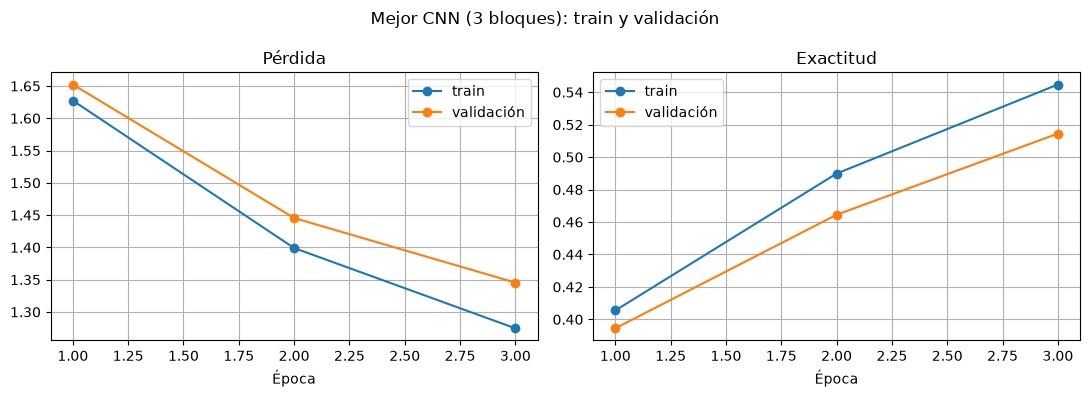

,capa,salida (batch=1),parámetros
0,features.0,"(1, 32, 32, 32)",896
1,features.1,"(1, 32, 32, 32)",0
2,features.2,"(1, 32, 16, 16)",0
3,features.3,"(1, 64, 16, 16)","18,496"
4,features.4,"(1, 64, 16, 16)",0
5,features.5,"(1, 64, 8, 8)",0
6,features.6,"(1, 96, 8, 8)","55,392"
7,features.7,"(1, 96, 8, 8)",0
8,features.8,"(1, 96, 4, 4)",0
9,pool,"(1, 96, 4, 4)",0


Forward de prueba: entrada (1, 3, 32, 32) -> salida (1, 10)
Total p.numel(): 272,810


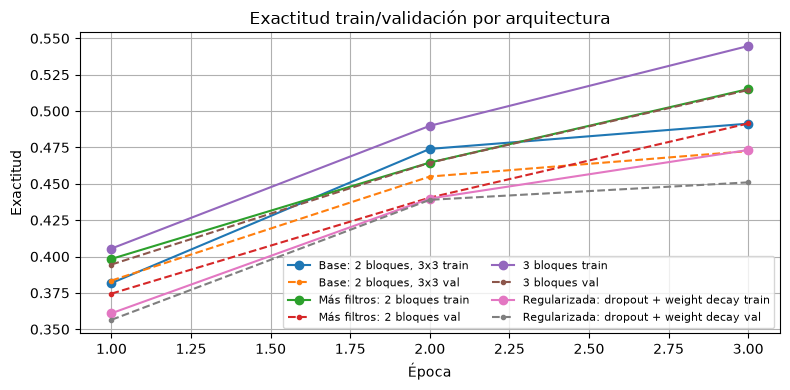

Lectura: una brecha train-validación que crece indica sobreajuste. Dropout, weight decay y selección temprana pueden reducirla; compare las curvas y la tabla obtenidas en esta corrida.


In [4]:
class CNN(nn.Module):
    def __init__(self, channels=(32, 64), kernel_size=3, hidden=128, dropout=0.3):
        super().__init__()
        layers, in_channels = [], 3
        for out_channels in channels:
            layers.extend([
                nn.Conv2d(in_channels, out_channels, kernel_size, padding=kernel_size // 2),
                nn.ReLU(inplace=True), nn.MaxPool2d(2)])
            in_channels = out_channels
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(in_channels * 4 * 4, hidden), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden, 10))
    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

variantes = {
    'Base: 2 bloques, 3x3': {'channels': (32, 64), 'kernel_size': 3, 'hidden': 128, 'dropout': 0.2, 'wd': 0.0},
    'Más filtros: 2 bloques': {'channels': (48, 96), 'kernel_size': 3, 'hidden': 128, 'dropout': 0.2, 'wd': 0.0},
    '3 bloques': {'channels': (32, 64, 96), 'kernel_size': 3, 'hidden': 128, 'dropout': 0.2, 'wd': 0.0},
    'Regularizada: dropout + weight decay': {'channels': (32, 64), 'kernel_size': 3, 'hidden': 128, 'dropout': 0.5, 'wd': 1e-3},
}
resultados, cnn_histories, cnn_models = [], {}, {}
for indice, (nombre, cfg) in enumerate(variantes.items()):
    print('\nVariante:', nombre)
    modelo, hist, tr_acc, va_acc = entrenar(
        CNN(cfg['channels'], cfg['kernel_size'], cfg['hidden'], cfg['dropout']),
        epochs=EPOCHS, weight_decay=cfg['wd'], patience=2, seed=SEED + indice + 1)
    params = sum(p.numel() for p in modelo.parameters())
    resultados.append({'variante': nombre, 'parámetros': params,
                       'exactitud train': tr_acc, 'exactitud validación': va_acc})
    cnn_histories[nombre], cnn_models[nombre] = hist, modelo

tabla_variantes = pd.DataFrame(resultados).sort_values(
    'exactitud validación', ascending=False).reset_index(drop=True)
display(tabla_variantes.style.format({'parámetros': '{:,}',
                                      'exactitud train': '{:.3f}',
                                      'exactitud validación': '{:.3f}'}))
nombre_mejor = tabla_variantes.loc[0, 'variante']
best_cnn = cnn_models[nombre_mejor]
best_history = cnn_histories[nombre_mejor]
print('Mejor arquitectura seleccionada exclusivamente por validación:', nombre_mejor)
fila_mejor = tabla_variantes.iloc[0]
fila_base = tabla_variantes.loc[tabla_variantes['variante'] == 'Base: 2 bloques, 3x3'].iloc[0]
fila_reg = tabla_variantes.loc[tabla_variantes['variante'] == 'Regularizada: dropout + weight decay'].iloc[0]
brecha = float(fila_mejor['exactitud train'] - fila_mejor['exactitud validación'])
print(f"Base: validación={fila_base['exactitud validación']:.3f}; mejor ({nombre_mejor}): "
      f"validación={fila_mejor['exactitud validación']:.3f}. Regularizada: "
      f"train={fila_reg['exactitud train']:.3f}, validación={fila_reg['exactitud validación']:.3f}.")
if brecha > 0.05:
    print(f'La brecha train-validación ({brecha:.3f}) sugiere sobreajuste; dropout, weight decay y '
          'parada temprana son controles aplicados en las variantes.')
else:
    print(f'No se observa una brecha positiva grande train-validación ({brecha:.3f}) en estas épocas; '
          'la comparación regularizada permite evaluar el efecto de dropout y weight decay.')
if fila_reg['exactitud validación'] < fila_base['exactitud validación']:
    print('En esta corrida la regularización fuerte no mejoró la validación frente a la base; '
          'con pocas épocas pudo limitar el aprendizaje en vez de corregir sobreajuste.')
else:
    print('En esta corrida la regularización mejoró la validación frente a la base.')

graficar_historia(best_history, f'Mejor CNN ({nombre_mejor}): train y validación')

# Resumen verificable de forma de salida y parámetros por módulo hoja.
def resumen_capas(model):
    filas, hooks = [], []
    def registrar(nombre):
        def hook(modulo, entradas, salida):
            if isinstance(salida, torch.Tensor):
                nparams = sum(p.numel() for p in modulo.parameters(recurse=False))
                filas.append({'capa': nombre, 'salida (batch=1)': tuple(salida.shape),
                              'parámetros': nparams})
        return hook
    for nombre, modulo in model.named_modules():
        if nombre and not any(modulo.children()):
            hooks.append(modulo.register_forward_hook(registrar(nombre)))
    model.eval()
    with torch.no_grad():
        salida = model(torch.zeros(1, 3, 32, 32, device=device))
    for hook in hooks:
        hook.remove()
    assert tuple(salida.shape) == (1, 10)
    display(pd.DataFrame(filas).style.format({'parámetros': '{:,}'}))
    total_directo = sum(p.numel() for p in model.parameters())
    print(f'Forward de prueba: entrada (1, 3, 32, 32) -> salida {tuple(salida.shape)}')
    print(f'Total p.numel(): {total_directo:,}')

resumen_capas(best_cnn)

# Comparar las curvas para discutir generalización y el efecto de regularizar.
fig, ax = plt.subplots(figsize=(8, 4))
for nombre, hist in cnn_histories.items():
    ax.plot(range(1, len(hist['train_acc']) + 1), hist['train_acc'], marker='o', label=f'{nombre} train')
    ax.plot(range(1, len(hist['val_acc']) + 1), hist['val_acc'], marker='.', linestyle='--', label=f'{nombre} val')
ax.set(xlabel='Época', ylabel='Exactitud', title='Exactitud train/validación por arquitectura')
ax.grid(True); ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()
print('Lectura: una brecha train-validación que crece indica sobreajuste. Dropout, weight decay '
      'y selección temprana pueden reducirla; compare las curvas y la tabla obtenidas en esta corrida.')

## 5. Evaluación final y análisis de errores

Esta sección consulta el conjunto de prueba por primera vez. Las dos exactitudes de prueba se calculan y reportan juntas una sola vez. La matriz de confusión y los ejemplos de error usan las predicciones de la CNN elegida por validación.

         modelo parámetros exactitud validación exactitud prueba
            MLP    789,258                0.404            0.411
CNN (3 bloques)    272,810                0.514            0.515


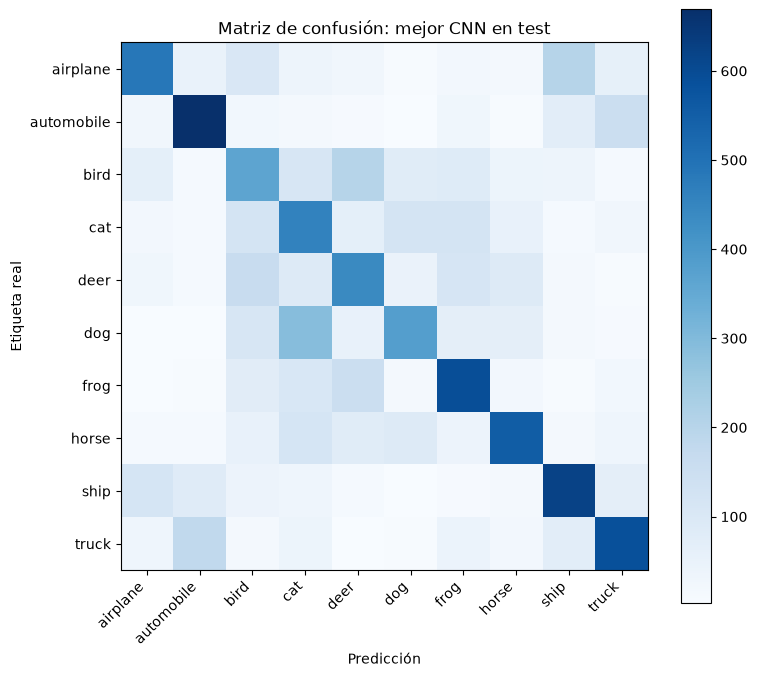

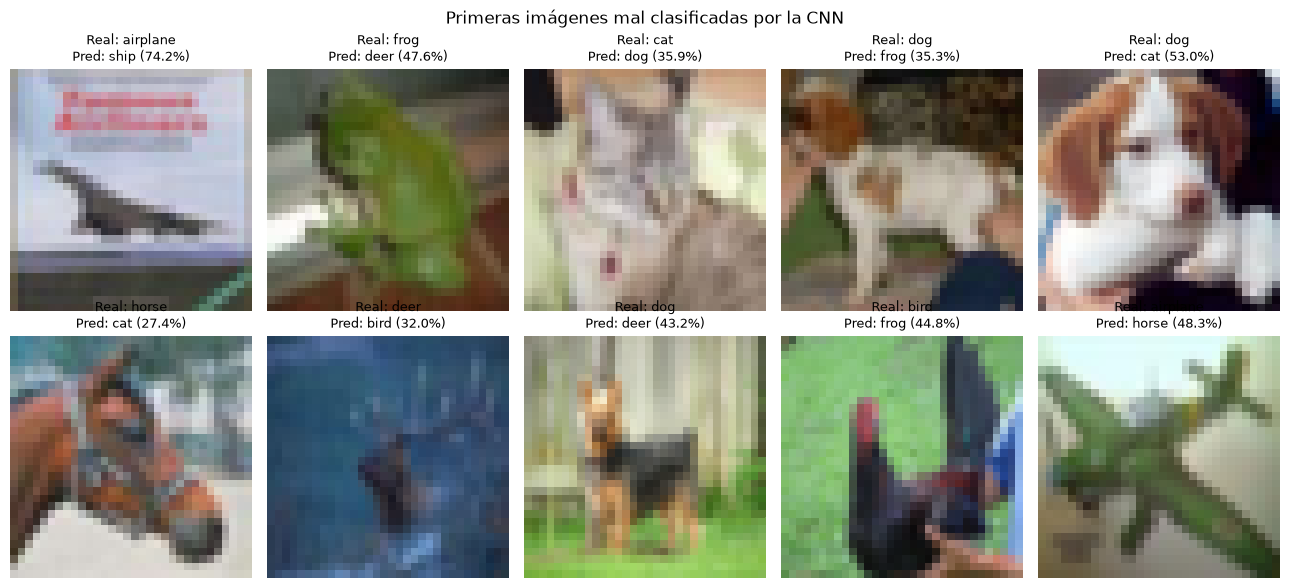

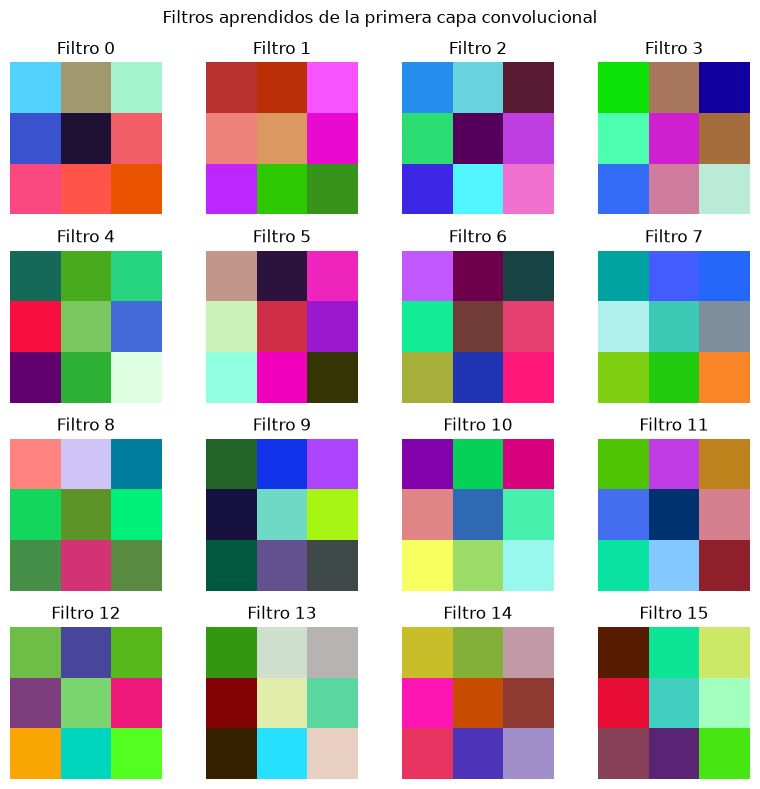

Pesos guardados en: C:\Users\VICTUS\Documents\VSC\IA\Tarea4\cifar10_best_cnn.pth
Carga de state_dict verificada.
La CNN usa 272,810 parámetros frente a 789,258 del MLP: la convolución comparte filtros locales y aprovecha la estructura espacial de la imagen.

Interpretación: una CNN suele aprovechar mejor la estructura espacial porque comparte filtros locales y construye representaciones jerárquicas; el MLP aplana la imagen y no incorpora esa estructura. Use la tabla de parámetros y exactitud de esta corrida para respaldar la comparación. Los filtros iniciales suelen responder a bordes, colores o texturas simples; las capas posteriores combinan esos patrones. Con pocas épocas, estos resultados son preliminares y dependen del hardware.


In [5]:
def predecir(model, loader):
    model.eval()
    predicciones, etiquetas, probabilidades = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            logits = model(preparar_lote(images))
            probs = logits.softmax(dim=1)
            predicciones.append(probs.argmax(dim=1).cpu())
            probabilidades.append(probs.cpu())
            etiquetas.append(labels)
    return torch.cat(predicciones), torch.cat(etiquetas), torch.cat(probabilidades)

pred_mlp, y_prueba, _ = predecir(mlp, test_loader)
pred_cnn, y_prueba_cnn, prob_cnn = predecir(best_cnn, test_loader)
assert torch.equal(y_prueba, y_prueba_cnn)
mlp_test_acc = (pred_mlp == y_prueba).float().mean().item()
cnn_test_acc = (pred_cnn == y_prueba).float().mean().item()
cnn_params = sum(p.numel() for p in best_cnn.parameters())
comparacion = pd.DataFrame([
    {'modelo': 'MLP', 'parámetros': mlp_params, 'exactitud validación': mlp_val_acc,
     'exactitud prueba': mlp_test_acc},
    {'modelo': f'CNN ({nombre_mejor})', 'parámetros': cnn_params,
     'exactitud validación': float(tabla_variantes.iloc[0]['exactitud validación']),
     'exactitud prueba': cnn_test_acc},
])
print(comparacion.to_string(index=False, formatters={
    'parámetros': lambda n: f'{n:,}',
    'exactitud validación': lambda x: f'{x:.3f}',
    'exactitud prueba': lambda x: f'{x:.3f}'}))

# Matriz de confusión: filas = clase real, columnas = predicción.
confusion = torch.bincount(y_prueba * 10 + pred_cnn, minlength=100).reshape(10, 10).numpy()
fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(confusion, cmap='Blues')
ax.set(xticks=range(10), yticks=range(10), xticklabels=class_names,
       yticklabels=class_names, xlabel='Predicción', ylabel='Etiqueta real',
       title='Matriz de confusión: mejor CNN en test')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
fig.colorbar(image, ax=ax); plt.tight_layout(); plt.show()

# Ejemplos mal clasificados; se muestra la probabilidad asignada a la clase predicha.
errores = torch.where(pred_cnn != y_prueba)[0][:10]
if len(errores) == 0:
    print('No hubo errores de clasificación en test.')
else:
    fig, axes = plt.subplots(2, 5, figsize=(13, 6))
    for ax, idx in zip(axes.flat, errores):
        imagen = x_test_np[int(idx)].transpose(1, 2, 0)
        clase_pred = int(pred_cnn[idx])
        ax.imshow(imagen)
        ax.set_title(f'Real: {class_names[int(y_prueba[idx])]}'
                     f'\nPred: {class_names[clase_pred]} ({prob_cnn[idx, clase_pred]:.1%})', fontsize=9)
        ax.axis('off')
    for ax in axes.flat[len(errores):]:
        ax.axis('off')
    plt.suptitle('Primeras imágenes mal clasificadas por la CNN')
    plt.tight_layout(); plt.show()

# Filtros de la primera convolución, normalizados individualmente para visualización.
conv1 = next(module for module in best_cnn.modules() if isinstance(module, nn.Conv2d))
filtros = conv1.weight.detach().cpu()
n_filtros = min(16, len(filtros))
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    if i < n_filtros:
        filtro = filtros[i]
        filtro = (filtro - filtro.min()) / (filtro.max() - filtro.min() + 1e-8)
        ax.imshow(filtro.permute(1, 2, 0))
        ax.set_title(f'Filtro {i}')
    ax.axis('off')
plt.suptitle('Filtros aprendidos de la primera capa convolucional')
plt.tight_layout(); plt.show()

# Guardado de los pesos de la CNN final seleccionada, sin objetos Python serializados.
ruta_pesos = OUTPUT_DIR / 'cifar10_best_cnn.pth'
torch.save(best_cnn.state_dict(), ruta_pesos)
print('Pesos guardados en:', ruta_pesos.resolve())

import json
cfg_final = variantes[nombre_mejor]
ruta_config = OUTPUT_DIR / 'cifar10_best_cnn_config.json'
with open(ruta_config, 'w', encoding='utf-8') as archivo:
    json.dump({'channels': list(cfg_final['channels']),
               'kernel_size': cfg_final['kernel_size'], 'hidden': cfg_final['hidden'],
               'dropout': cfg_final['dropout']}, archivo, indent=2)

# Comprobación de carga dentro de esta ejecución.
modelo_cargado = CNN(cfg_final['channels'], cfg_final['kernel_size'],
                     cfg_final['hidden'], cfg_final['dropout']).to(device)
modelo_cargado.load_state_dict(torch.load(ruta_pesos, map_location=device, weights_only=True))
modelo_cargado.eval()
print('Carga de state_dict verificada.')

print(f'La CNN usa {cnn_params:,} parámetros frente a {mlp_params:,} del MLP: '
      'la convolución comparte filtros locales y aprovecha la estructura espacial de la imagen.')
print('\nInterpretación: una CNN suele aprovechar mejor la estructura espacial porque comparte filtros '
      'locales y construye representaciones jerárquicas; el MLP aplana la imagen y no incorpora esa '
      'estructura. Use la tabla de parámetros y exactitud de esta corrida para respaldar la comparación. '
      'Los filtros iniciales suelen responder a bordes, colores o texturas simples; las capas posteriores '
      'combinan esos patrones. Con pocas épocas, estos resultados son preliminares y dependen del hardware.')

### Cargar el checkpoint sin volver a entrenar

En una sesión nueva, basta con ejecutar esta celda después de tener PyTorch disponible y estar en la carpeta `Tarea4` (no ejecute las celdas de entrenamiento). El archivo JSON guarda la configuración exacta seleccionada; el `.pth` contiene el `state_dict`.

In [6]:
import json
from pathlib import Path
import torch
from torch import nn

salida_dir = next((p for p in [Path.cwd(), Path.cwd() / 'Tarea4', Path.cwd().parent / 'Tarea4']
                   if (p / 'cifar10_best_cnn.pth').exists()), None)
if salida_dir is None:
    raise FileNotFoundError('No se encontró Tarea4/cifar10_best_cnn.pth')
with open(salida_dir / 'cifar10_best_cnn_config.json', encoding='utf-8') as archivo:
    config = json.load(archivo)

class CNNCheckpoint(nn.Module):
    def __init__(self, channels, kernel_size, hidden, dropout):
        super().__init__()
        layers, in_channels = [], 3
        for out_channels in channels:
            layers.extend([nn.Conv2d(in_channels, out_channels, kernel_size,
                                     padding=kernel_size // 2), nn.ReLU(inplace=True), nn.MaxPool2d(2)])
            in_channels = out_channels
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(in_channels * 4 * 4, hidden),
                                        nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 10))
    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

modelo_checkpoint = CNNCheckpoint(config['channels'], config['kernel_size'],
                                  config['hidden'], config['dropout'])
modelo_checkpoint.load_state_dict(torch.load(salida_dir / 'cifar10_best_cnn.pth',
                                             map_location='cpu', weights_only=True))
modelo_checkpoint.eval()
print('Checkpoint cargado sin entrenamiento; configuración:', config)

Checkpoint cargado sin entrenamiento; configuración: {'channels': [32, 64, 96], 'kernel_size': 3, 'hidden': 128, 'dropout': 0.2}
